# Credit Default Prediction and Customer Risk Profiling

## Project Overview

This project uses historical credit card customer data to investigate a practical financial-risk question:

> **Which customer characteristics and repayment behaviors are associated with credit card default, and can these patterns be translated into an interpretable customer risk profile?**

The project emphasizes a complete and understandable data science workflow rather than model complexity:

**Data Understanding → Exploratory Data Analysis → Feature Engineering → Predictive Modeling → Model Evaluation → Model Interpretation → Customer Risk Profiling → Business Conclusion**

### Project Objectives

1. Explore customer credit, repayment, billing, and payment behavior using charts and descriptive statistics.
2. Identify variables that show meaningful statistical associations with default.
3. Build baseline Logistic Regression and Random Forest models.
4. Compare the incremental contribution of demographic, repayment, billing, and payment feature groups.
5. Construct an interpretable, rule-based customer risk profile to examine which observed customer patterns are associated with higher default rates.

### Data and Methodology Note

The dataset is a local copy of the UCI Default of Credit Card Clients dataset. The target variable is `default.payment.next.month`.

The **High Risk** profile used later in the project is a descriptive, rule-based profile. It is not a model prediction label and should not be interpreted as a causal classification. All conclusions are limited to the current dataset and the feature definitions used in this project.


## 1. Data Understanding

**What are we doing here?**

We confirm the data source, the number of observations and variables, and the data types, then run a short checklist: missing values (1.1), duplicate records (1.2), the target variable (1.3), the codes used by the categorical and repayment-status columns (1.4 and 1.5), the distribution of the numeric variables (1.6), and finally we prepare the analysis dataset (1.7).

The dataset is a local copy of the UCI Default of Credit Card Clients dataset. The target variable `default.payment.next.month` is coded as 0 for no default and 1 for default.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


# Keep numeric tables readable: four decimals instead of the default six
pd.set_option("display.float_format", "{:.4f}".format)

# The notebook is run from the notebooks/ folder, so paths are relative to it.
# FIGURE_DIR and REPORTS_DIR are defined here so every later cell can reuse them.
DATA_PATH = Path("../dataset/default_of_credit_card_clients_dataset.csv")
FIGURE_DIR = Path("../figures")
REPORTS_DIR = Path("../reports")
FIGURE_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Data shape(rows, columns):", df.shape)
df.info()
df.head()


Data shape(rows, columns): (30000, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0000,2,2,1,24,2,2,-1,-1,...,0.0000,0.0000,0.0000,0.0000,689.0000,0.0000,0.0000,0.0000,0.0000,1
1,2,120000.0000,2,2,2,26,-1,2,0,0,...,3272.0000,3455.0000,3261.0000,0.0000,1000.0000,1000.0000,1000.0000,0.0000,2000.0000,1
2,3,90000.0000,2,2,2,34,0,0,0,0,...,14331.0000,14948.0000,15549.0000,1518.0000,1500.0000,1000.0000,1000.0000,1000.0000,5000.0000,0
3,4,50000.0000,2,2,1,37,0,0,0,0,...,28314.0000,28959.0000,29547.0000,2000.0000,2019.0000,1200.0000,1100.0000,1069.0000,1000.0000,0
4,5,50000.0000,1,2,1,57,-1,0,-1,0,...,20940.0000,19146.0000,19131.0000,2000.0000,36681.0000,10000.0000,9000.0000,689.0000,679.0000,0


In [2]:
# 1.1 Check missing values
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_rate": df.isna().mean()
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0]

if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary.sort_values("missing_count", ascending=False))

No missing values found.


If the check above reports no missing values, the current dataset does not require missing-value treatment. The median imputer used later in the modeling pipeline is kept as a standard safeguard for possible missing values; it is not evidence that this dataset currently has missing data.

In [3]:
# 1.2 Check duplicated records
# ID is only a row identifier, so duplicates are looked for after ignoring it.
# Repeat rows are reported and kept: dropping them is a judgement call, not an obvious error.
print("Duplicated rows (ignoring ID):", df.drop(columns=["ID"]).duplicated().sum())
print("Duplicated customer IDs:", df["ID"].duplicated().sum())


Duplicated rows (ignoring ID): 35
Duplicated customer IDs: 0


In [4]:
# 1.3 Check the target variable
# Completeness check only: the class balance itself is examined in section 2.1.
print("Missing values:", df["default.payment.next.month"].isna().sum())
print("Unique values:", sorted(df["default.payment.next.month"].unique()))


Missing values: 0
Unique values: [np.int64(0), np.int64(1)]


In [5]:
# 1.4 Check available codes in categorical and repayment-status columns
# Demographic variables: every code is printed, because the recoding step below depends on
# knowing which codes are rare or undocumented in the dataset description.
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().sort_index())

# The repayment status columns share one code space, so only the range is reported here.
# They are analysed in context in section 2.2.3.
for col in ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
    codes = df[col].value_counts().sort_index()
    print(f"{col}: {codes.size} distinct codes, from {codes.index.min()} to {codes.index.max()}")



--- SEX ---
SEX
1    11888
2    18112
Name: count, dtype: int64

--- EDUCATION ---
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

--- MARRIAGE ---
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64
PAY_0: 11 distinct codes, from -2 to 8
PAY_2: 11 distinct codes, from -2 to 8
PAY_3: 11 distinct codes, from -2 to 8
PAY_4: 11 distinct codes, from -2 to 8
PAY_5: 10 distinct codes, from -2 to 8
PAY_6: 10 distinct codes, from -2 to 8


In [6]:
# 1.5 Combine unclear/rare category codes
# Group education codes 0, 5 and 6 into code 4 (Other/Unknown).
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

# Group marriage code 0 into code 3 (Other).
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

print("EDUCATION after cleaning:")
print(df['EDUCATION'].value_counts().sort_index())
print("\nMARRIAGE after cleaning:")
print(df['MARRIAGE'].value_counts().sort_index())

EDUCATION after cleaning:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

MARRIAGE after cleaning:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


In [7]:
# 1.6 Summarize age, credit limit, bill amounts and payment amounts
num_cols = (
    ['LIMIT_BAL', 'AGE']
    + [f'BILL_AMT{i}' for i in range(1, 7)]
    + [f'PAY_AMT{i}' for i in range(1, 7)]
)
display(df[num_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0000,167484.3227,129747.6616,10000.0000,50000.0000,140000.0000,240000.0000,1000000.0000
AGE,30000.0000,35.4855,9.2179,21.0000,28.0000,34.0000,41.0000,79.0000
BILL_AMT1,30000.0000,51223.3309,73635.8606,-165580.0000,3558.7500,22381.5000,67091.0000,964511.0000
BILL_AMT2,30000.0000,49179.0752,71173.7688,-69777.0000,2984.7500,21200.0000,64006.2500,983931.0000
BILL_AMT3,30000.0000,47013.1548,69349.3874,-157264.0000,2666.2500,20088.5000,60164.7500,1664089.0000
BILL_AMT4,30000.0000,43262.9490,64332.8561,-170000.0000,2326.7500,19052.0000,54506.0000,891586.0000
BILL_AMT5,30000.0000,40311.4010,60797.1558,-81334.0000,1763.0000,18104.5000,50190.5000,927171.0000
BILL_AMT6,30000.0000,38871.7604,59554.1075,-339603.0000,1256.0000,17071.0000,49198.2500,961664.0000
PAY_AMT1,30000.0000,5663.5805,16563.2804,0.0000,1000.0000,2100.0000,5006.0000,873552.0000
PAY_AMT2,30000.0000,5921.1635,23040.8704,0.0000,833.0000,2009.0000,5000.0000,1684259.0000


In [8]:
# 1.7 Prepare the dataset for later analysis
# ID is only an identifier, so remove it from the analysis dataset.
df = df.drop(columns=['ID'])

# Use a shorter target name in later analysis and modeling.
df = df.rename(columns={'default.payment.next.month': 'default'})

# target_col is defined after the rename, so it always refers to a column that exists
target_col = "default"

print("Prepared dataset shape (rows, columns):", df.shape)
print("Target:", target_col, "| values:", sorted(df[target_col].unique()))


Prepared dataset shape (rows, columns): (30000, 24)
Target: default | values: [np.int64(0), np.int64(1)]


## 2. Exploratory Data Analysis (EDA)

**What are we doing here?**

We examine demographic characteristics, credit limits, repayment history, billing behavior, and payment behavior in relation to the default outcome.

The analysis focuses on **descriptive associations**. An observed relationship does not imply a causal relationship.


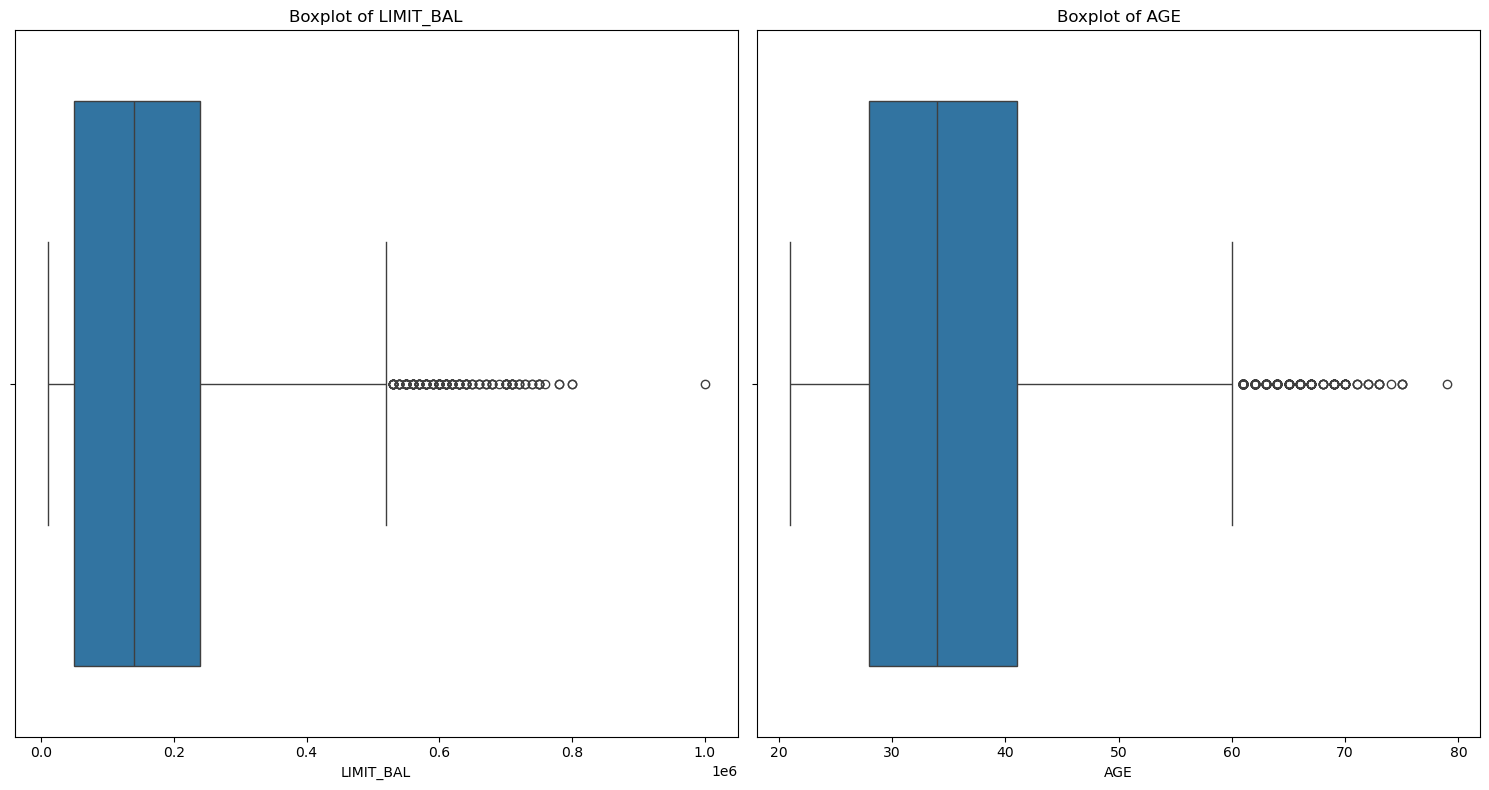

In [9]:

# Boxplots for the two main continuous variables (outlier check)
base_cols = ['LIMIT_BAL', 'AGE']

plt.figure(figsize=(15, 8))
for i, col in enumerate(base_cols):
    plt.subplot(1, 2, i+1)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()


### 2.1 Target Distribution

First, we check whether default and non-default customers are balanced. Because default customers are a minority class, later model evaluation should not rely on Accuracy alone.


In [10]:
target_summary = df["default"].value_counts().sort_index()
target_summary = target_summary.rename(index={0: "Non-default", 1: "Default"})

target_plot = pd.DataFrame({
    "count": target_summary,
    "proportion": target_summary / len(df)
})
target_plot["proportion_pct"] = target_plot["proportion"] * 100

target_plot[["count", "proportion_pct"]]

,count,proportion_pct
default,,
Non-default,23364,77.8800
Default,6636,22.1200


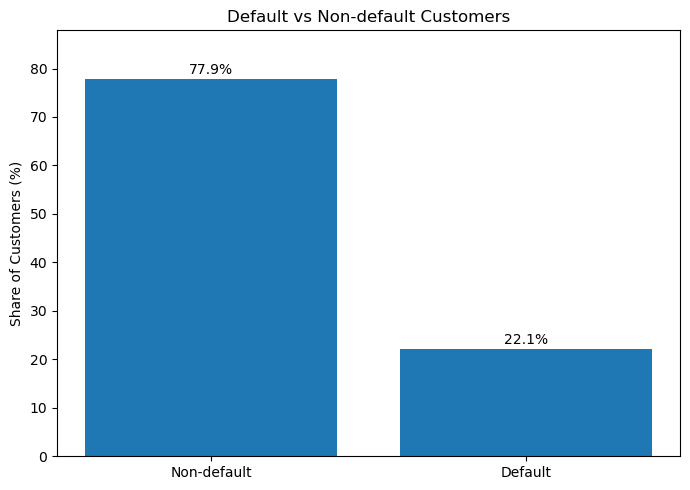

In [11]:
plt.figure(figsize=(7, 5))
plt.bar(target_plot.index, target_plot["proportion_pct"])
plt.ylabel("Share of Customers (%)")
plt.title("Default vs Non-default Customers")
for i, value in enumerate(target_plot["proportion_pct"]):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")
plt.ylim(0, max(target_plot["proportion_pct"]) + 10)
plt.tight_layout()
plt.show()

**Observation:** Default customers account for about 22% of the sample, indicating a meaningful class imbalance. The modeling stage therefore reports Precision, Recall, F1-score, ROC-AUC, and PR-AUC in addition to Accuracy.


### 2.2 Customer Characteristics

This section walks through the customer variables one by one: demographics (2.2.1), credit limit (2.2.2), delay behavior (2.2.3), billing behavior (2.2.4), payment amounts (2.2.5), and the payment-to-bill relationship (2.2.6). This order supports feature selection in section 3, and section 6 then compares the contribution of the behavioral groups cumulatively.

Each part describes how the observed default rate changes across groups of a single variable. Very small subgroups are interpreted cautiously and are not used for strong conclusions.

#### 2.2.1 Demographic Characteristics

In [12]:
# 2.2.1 Demographic Characteristics

for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    summary = df.groupby(col)[target_col].agg(
        count="count",
        default_rate="mean"
    ).reset_index()
    summary["share"] = summary["count"] / summary["count"].sum()
    display(summary)

age_bins = [20, 30, 40, 50, 60, 100]
age_labels = ["20-29", "30-39", "40-49", "50-59", "60+"]
df["AGE-binned"] = pd.cut(
    df["AGE"], bins=age_bins, labels=age_labels,
    right=False, include_lowest=True
)

print("\n--- AGE-binned ---")
age_default = df.groupby("AGE-binned", observed=True)[target_col].agg(
    count="count",
    default_rate="mean"
).reset_index()
age_default["share"] = age_default["count"] / age_default["count"].sum()
display(age_default)


,SEX,count,default_rate,share
0,1,11888,0.2417,0.3963
1,2,18112,0.2078,0.6037


,EDUCATION,count,default_rate,share
0,1,10585,0.1923,0.3528
1,2,14030,0.2373,0.4677
2,3,4917,0.2516,0.1639
3,4,468,0.0705,0.0156


,MARRIAGE,count,default_rate,share
0,1,13659,0.2347,0.4553
1,2,15964,0.2093,0.5321
2,3,377,0.2361,0.0126



--- AGE-binned ---


,AGE-binned,count,default_rate,share
0,20-29,9618,0.2284,0.3206
1,30-39,11238,0.2025,0.3746
2,40-49,6464,0.2297,0.2155
3,50-59,2341,0.2486,0.0780
4,60+,339,0.2832,0.0113


**Interpretation:** Observed default rates do vary across demographic groups.

Sex: Males (SEX=1) show a slightly higher default rate (24.17%) compared to females (SEX=2, 20.78%).

Education: There is a clear trend where lower education levels correspond to higher default rates (Graduate: 19.23%, University: 23.73%, High School: 25.16%). However, the "Others" category (EDUCATION=4) has only 468 observations and an unusually low default rate (7.05%).

Marriage: Default rates are fairly similar between married (23.47%) and single (20.93%) customers. The "Others" category (MARRIAGE=3) shows a 23.61% default rate but contains only 377 observations.

The demographic features (SEX, EDUCATION, MARRIAGE) show only marginal predictive power. Apart from the two small Other groups, the observed default rates stay in a narrow band of roughly 19% to 25%, and no single demographic group stands out with a substantially higher risk.

This suggests that static demographic labels are insufficient for effective risk discrimination. Consequently, these variables will be treated primarily as control features rather than core determinants. The primary predictive power for default will be explored in the financial and behavioral characteristics in the next section.




#### 2.2.2 Credit Limit

We first examine the distribution of `LIMIT_BAL`, then divide customers into five quantile groups and compare their observed default rates.


In [13]:
print(df["LIMIT_BAL"].describe())


count     30000.0000
mean     167484.3227
std      129747.6616
min       10000.0000
25%       50000.0000
50%      140000.0000
75%      240000.0000
max     1000000.0000
Name: LIMIT_BAL, dtype: float64


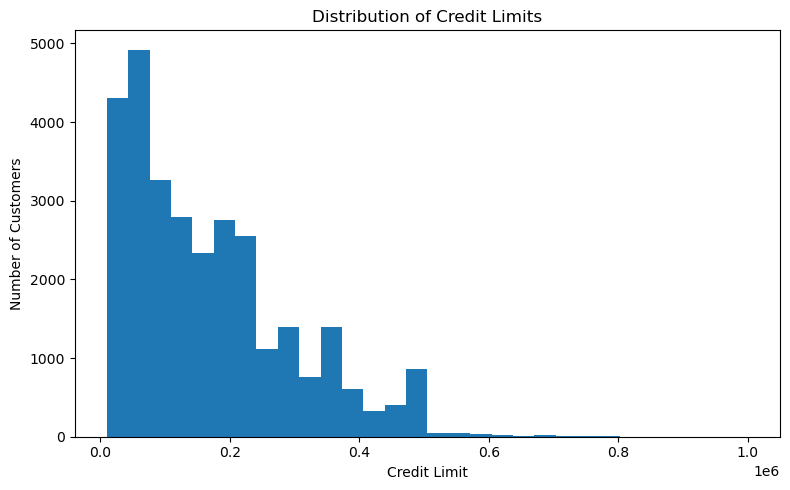

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["LIMIT_BAL"], bins=30)
plt.xlabel("Credit Limit")
plt.ylabel("Number of Customers")
plt.title("Distribution of Credit Limits")
plt.tight_layout()
plt.show()


In [15]:
df["LIMIT_BAL_group"] = pd.qcut(
    df["LIMIT_BAL"], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)
credit_default = df.groupby("LIMIT_BAL_group", observed=True)[target_col].agg(
    count="count", default_rate="mean"
)
credit_default

,count,default_rate
LIMIT_BAL_group,,
Q1,7676,0.3179
Q2,4822,0.2580
Q3,6123,0.1986
Q4,5421,0.1686
Q5,5958,0.1380


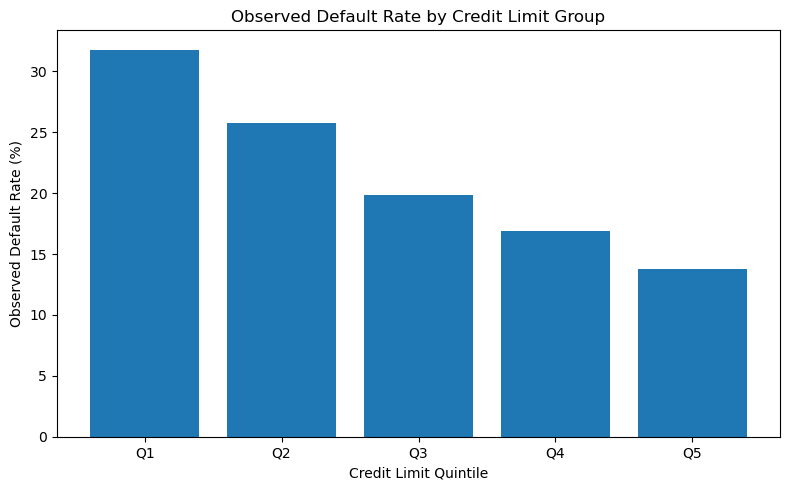

In [16]:
credit_plot = credit_default.copy()
credit_plot["default_rate_pct"] = credit_plot["default_rate"] * 100

plt.figure(figsize=(8, 5))
plt.bar(credit_plot.index.astype(str), credit_plot["default_rate_pct"])
plt.xlabel("Credit Limit Quintile")
plt.ylabel("Observed Default Rate (%)")
plt.title("Observed Default Rate by Credit Limit Group")
plt.tight_layout()
plt.show()

**Interpretation:** Customers in the lower credit-limit groups show higher observed default rates, so credit limit has an overall negative association with default in this dataset. The lowest group (Q1) has the highest rate at about 31.8%. This is a statistical association, not evidence that a lower credit limit causes default.


#### 2.2.3 Repayment Behavior

Historical repayment status is one of the most important feature groups in this project. `PAY_0`, the most recent month, is shown in full as the representative column, and a compact comparison checks whether the same pattern repeats across all six status columns. `delay_months` is then constructed as the behavioral feature used later in modeling and in the customer risk profile.


In [17]:
# PAY_0 is the September status and PAY_2 to PAY_6 are the following months.
# The dataset has no PAY_1 column, so the six status columns below are all of them.
pay_status_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

# PAY_0 is the most recent month, so it is shown in full as the representative column.
# Values above 0 mean the customer was behind on that month's payment.
print("--- PAY_0 (most recent month) ---")
pay0_default = df.groupby("PAY_0")[target_col].agg(
    count="count", default_rate="mean"
).reset_index()
pay0_default["share"] = pay0_default["count"] / pay0_default["count"].sum()
display(pay0_default)

# The other months use the same code scale. Instead of six near-identical tables, one compact
# comparison shows that the pattern repeats in every month of the six-month window.
compare_rows = []
for col in pay_status_cols:
    compare_rows.append({
        "Status column": col,
        "Default rate, no delay (code <= 0)": df.loc[df[col] <= 0, target_col].mean(),
        "Default rate, 2+ months overdue": df.loc[df[col] >= 2, target_col].mean(),
    })
pay_status_compare = pd.DataFrame(compare_rows)
display(pay_status_compare.round(4))


--- PAY_0 (most recent month) ---


,PAY_0,count,default_rate,share
0,-2,2759,0.1323,0.0920
1,-1,5686,0.1678,0.1895
2,0,14737,0.1281,0.4912
3,1,3688,0.3395,0.1229
4,2,2667,0.6914,0.0889
5,3,322,0.7578,0.0107
6,4,76,0.6842,0.0025
7,5,26,0.5000,0.0009
8,6,11,0.5455,0.0004
9,7,9,0.7778,0.0003


,Status column,"Default rate, no delay (code <= 0)","Default rate, 2+ months overdue"
0,PAY_0,0.1383,0.6955
1,PAY_2,0.1627,0.5603
2,PAY_3,0.1719,0.5229
3,PAY_4,0.1796,0.5353
4,PAY_5,0.1845,0.5556
5,PAY_6,0.1867,0.5232


In [18]:
# delay_months counts how many of the six months have a positive delay value.
# Values of -2, -1 and 0 all mean "no recorded delay", so only values above 0 are counted.
df["delay_months"] = (df[pay_status_cols] > 0).sum(axis=1)

delay_default = df.groupby("delay_months")[target_col].agg(
    count="count", default_rate="mean"
).reset_index()
delay_default["share"] = delay_default["count"] / delay_default["count"].sum()
display(delay_default)


,delay_months,count,default_rate,share
0,0,19931,0.1171,0.6644
1,1,4426,0.2982,0.1475
2,2,1899,0.3876,0.0633
3,3,1154,0.5087,0.0385
4,4,951,0.5731,0.0317
5,5,298,0.5738,0.0099
6,6,1341,0.7032,0.0447


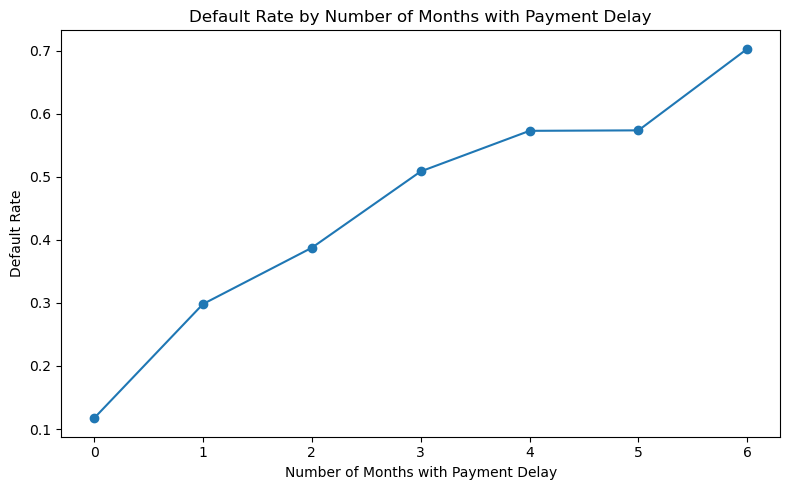

In [19]:
delay_rate = delay_default["default_rate"]

plt.figure(figsize=(8, 5))
plt.plot(delay_rate.index, delay_rate.values, marker="o")
plt.xlabel("Number of Months with Payment Delay")
plt.ylabel("Default Rate")
plt.title("Default Rate by Number of Months with Payment Delay")
plt.tight_layout()
plt.show()

**Interpretation:** `delay_months` shows a clear positive association with the observed default rate. It is therefore an important EDA variable and a core repayment feature in the predictive models.


#### 2.2.4 Billing Behavior

We look at the distribution of the six monthly bill variables. They are consistently right-skewed (skewness from 2.66 to 3.09) with 6.7% to 13.4% of the rows recorded as exactly zero. Because the six monthly columns are highly redundant, one representative distribution plot (BILL_AMT1) is kept for visualization, and the six columns are aggregated into `avg_bill_amt` and `bill_amt_std` to capture the overall bill level and its month-to-month volatility.


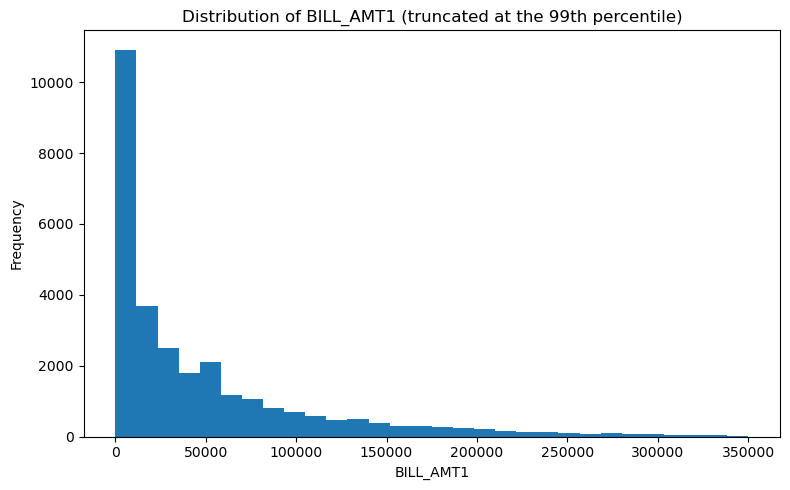

In [20]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]

# BILL_AMT1 is used as the representative monthly bill distribution.
# Bills are heavily right-skewed, so the x-axis stops at the 99th percentile.
plt.figure(figsize=(8, 5))
plt.hist(df["BILL_AMT1"], bins=30, range=(0, df["BILL_AMT1"].quantile(0.99)))
plt.xlabel("BILL_AMT1")
plt.ylabel("Frequency")
plt.title("Distribution of BILL_AMT1 (truncated at the 99th percentile)")
plt.tight_layout()
plt.show()


In [21]:
for col in bill_cols:
    print(f"{col}: skew={df[col].skew():.2f}, zero%={(df[col]==0).mean():.1%}")

BILL_AMT1: skew=2.66, zero%=6.7%
BILL_AMT2: skew=2.71, zero%=8.4%
BILL_AMT3: skew=3.09, zero%=9.6%
BILL_AMT4: skew=2.82, zero%=10.7%
BILL_AMT5: skew=2.88, zero%=11.7%
BILL_AMT6: skew=2.85, zero%=13.4%


In [22]:
# A negative bill amount is reported as a credit or overpayment balance.
# These values are kept as reported instead of being replaced or removed.
negative_bill_rows = (df[bill_cols] < 0).any(axis=1).sum()
print("Rows with at least one negative BILL_AMT:", negative_bill_rows)
print("Share of all rows: {:.2%}".format(negative_bill_rows / len(df)))

# Two summary features replace the six monthly bill columns:
# the average bill level and the month-to-month bill volatility
df["avg_bill_amt"] = df[bill_cols].mean(axis=1)
df["bill_amt_std"] = df[bill_cols].std(axis=1)

bill_features_summary = df[["avg_bill_amt", "bill_amt_std"]].describe()
bill_features_summary


Rows with at least one negative BILL_AMT: 1930
Share of all rows: 6.43%


,avg_bill_amt,bill_amt_std
count,30000.0000,30000.0000
mean,44976.9452,12077.7875
std,63260.7219,20302.1491
min,-56043.1667,0.0000
25%,4781.3333,1549.9352
50%,21051.8333,4579.6622
75%,57104.4167,14352.2596
max,877313.8333,647788.0511


In [23]:
# Split each billing feature into five quantile groups and compare default rates.
# Results are stored so the plotting cell can reuse them instead of recomputing the grouping.
bill_group_results = []

for col in ["avg_bill_amt", "bill_amt_std"]:
    group_col = f"{col}_group"
    df[group_col] = pd.qcut(df[col], q=5, duplicates="drop")
    summary = df.groupby(group_col, observed=True)[target_col].agg(
        count="count", default_rate="mean"
    ).reset_index()
    summary["share"] = summary["count"] / summary["count"].sum()
    display(summary)
    bill_group_results.append((col, summary))


,avg_bill_amt_group,count,default_rate,share
0,"(-56043.168, 2861.167]",6000,0.2542,0.2000
1,"(2861.167, 13764.1]",6000,0.1915,0.2000
2,"(13764.1, 31478.833]",6000,0.2428,0.2000
3,"(31478.833, 72535.133]",6000,0.2152,0.2000
4,"(72535.133, 877313.833]",6000,0.2023,0.2000


,bill_amt_std_group,count,default_rate,share
0,"(-0.001, 1232.262]",6000,0.3048,0.2000
1,"(1232.262, 2909.883]",6000,0.2917,0.2000
2,"(2909.883, 7391.302]",6000,0.1817,0.2000
3,"(7391.302, 17578.731]",6000,0.1648,0.2000
4,"(17578.731, 647788.051]",6000,0.1630,0.2000


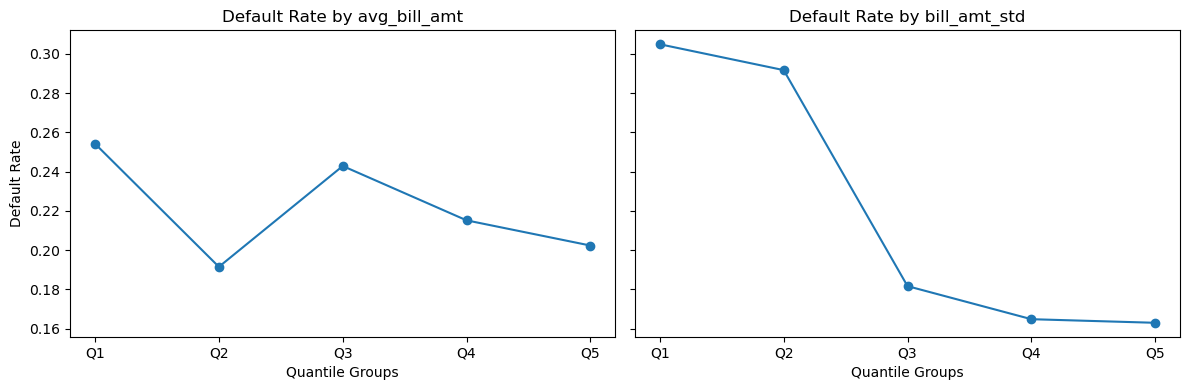

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, (col, summary) in zip(axes, bill_group_results):
    ax.plot(range(len(summary)), summary["default_rate"], marker="o")
    ax.set_title(f"Default Rate by {col}")
    ax.set_xticks(range(len(summary)))
    ax.set_xticklabels([f"Q{i+1}" for i in range(len(summary))])
    ax.set_xlabel("Quantile Groups")

axes[0].set_ylabel("Default Rate")
plt.tight_layout()
plt.show()


Observation: 1,930 rows (6.43%) contain at least one negative BILL_AMT, which is reported as a credit or overpayment balance. These values are kept as reported instead of being replaced or removed. BILL_AMT1 is still strongly right-skewed (skewness = 2.66) with about 6.7% of the rows recorded as exactly zero, so two aggregate features were built: avg_bill_amt and bill_amt_std. The observed default rate is non-linear across avg_bill_amt quintiles (25.4%, 19.2%, 24.3%, 21.5%, 20.2%), while bill_amt_std decreases steadily from the least volatile group (Q1, 30.5%) to the most volatile group (Q5, 16.3%). Bill volatility therefore carries a steadier signal than the average bill amount, and both features are kept for modeling.


#### 2.2.5 Payment Behavior

The original notebook contained two highly similar histograms for `PAY_AMT1`. We retain one representative plot, truncated at the 99th percentile for visualization, and use the six monthly payment variables to construct average payment and payment volatility.


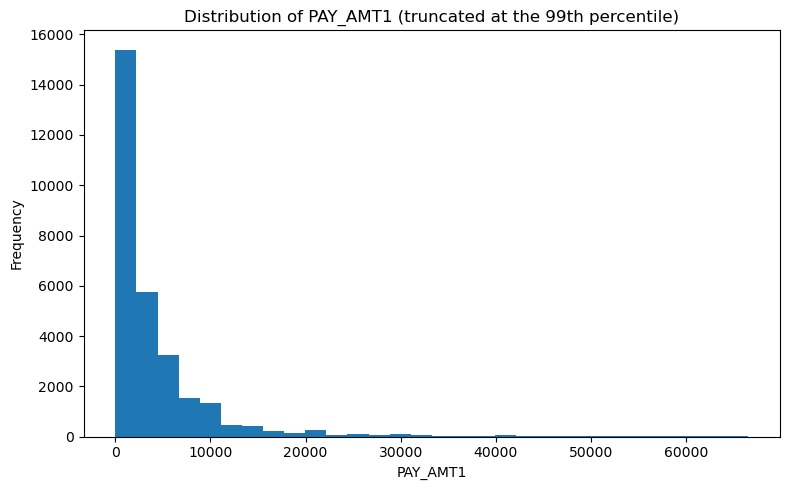

In [25]:
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

# PAY_AMT1 is used as the representative monthly payment distribution.
# Payment amounts are extremely right-skewed, so the x-axis stops at the 99th percentile.
plt.figure(figsize=(8, 5))
plt.hist(df["PAY_AMT1"], bins=30, range=(0, df["PAY_AMT1"].quantile(0.99)))
plt.xlabel("PAY_AMT1")
plt.ylabel("Frequency")
plt.title("Distribution of PAY_AMT1 (truncated at the 99th percentile)")
plt.tight_layout()
plt.show()


In [26]:
for col in payment_cols:
    print(f"{col}: skew={df[col].skew():.2f}, zero%={(df[col]==0).mean():.1%}")

PAY_AMT1: skew=14.67, zero%=17.5%
PAY_AMT2: skew=30.45, zero%=18.0%
PAY_AMT3: skew=17.22, zero%=19.9%
PAY_AMT4: skew=12.90, zero%=21.4%
PAY_AMT5: skew=11.13, zero%=22.3%
PAY_AMT6: skew=10.64, zero%=23.9%


In [27]:
# Two summary features replace the six monthly payment columns:
# the average payment level and the month-to-month payment volatility.
# payment_cols is defined above, together with the payment distribution plot.
df["avg_payment"] = df[payment_cols].mean(axis=1)
df["payment_std"] = df[payment_cols].std(axis=1)

# Split both features into five quantile groups and compare default rates
payment_group_results = []

for col in ["avg_payment", "payment_std"]:
    group_col = f"{col}_group"
    df[group_col] = pd.qcut(df[col], q=5, duplicates="drop")
    summary = df.groupby(group_col, observed=True)[target_col].agg(
        count="count", default_rate="mean"
    ).reset_index()
    summary["share"] = summary["count"] / summary["count"].sum()
    display(summary)
    payment_group_results.append((col, summary))


,avg_payment_group,count,default_rate,share
0,"(-0.001, 913.467]",6000,0.3163,0.2000
1,"(913.467, 1755.033]",6000,0.2765,0.2000
2,"(1755.033, 3341.133]",6000,0.2202,0.2000
3,"(3341.133, 6810.733]",6000,0.1725,0.2000
4,"(6810.733, 627344.333]",6000,0.1205,0.2000


,payment_std_group,count,default_rate,share
0,"(-0.001, 502.24]",6000,0.2538,0.2000
1,"(502.24, 1020.621]",6010,0.2439,0.2003
2,"(1020.621, 2041.241]",6008,0.2655,0.2003
3,"(2041.241, 5717.709]",5982,0.2086,0.1994
4,"(5717.709, 650098.339]",6000,0.1340,0.2000


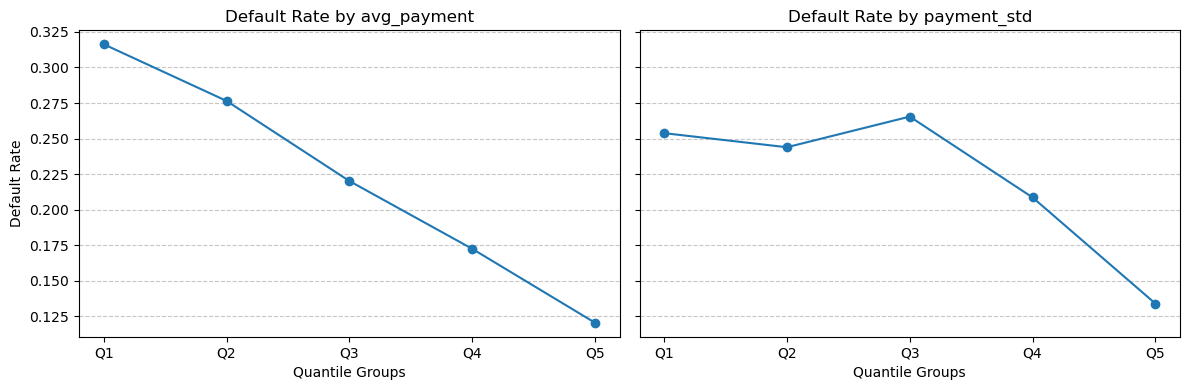

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, (col, summary) in zip(axes, payment_group_results):
    ax.plot(range(len(summary)), summary["default_rate"], marker="o")
    ax.set_title(f"Default Rate by {col}")
    ax.set_xticks(range(len(summary)))
    ax.set_xticklabels([f"Q{i+1}" for i in range(len(summary))])
    ax.set_xlabel("Quantile Groups")
    ax.grid(axis="y", linestyle="--", alpha=0.7)

axes[0].set_ylabel("Default Rate")
plt.tight_layout()
plt.show()


Observation: Payment amounts are heavily right-skewed with many zero values. After aggregation, avg_payment decreases steadily across quintiles (31.6%, 27.7%, 22.0%, 17.3%, 12.1%), so customers who pay more on average default less often. payment_std is less orderly: it peaks in Q3 (26.6%) before falling to 13.4% in Q5. The average payment level is therefore the steadier of the two payment features, while payment volatility adds a weaker and less monotonic signal.


#### 2.2.6 Payment-to-Bill Ratio

This is a key feature-engineering step. The ratio is not a strict current-period repayment rate. Instead, it is a behavioral proxy based on cumulative six-month payments and bill amounts.

When `total_bill <= 0`, the ratio cannot be meaningfully calculated. Those observations are kept as missing and flagged with a `ratio_missing` indicator, so the models can still use them.


In [29]:
# The payment-to-bill ratio compares the six-month payment total with the six-month bill total.
# When the cumulative bill is not positive, a meaningful ratio cannot be calculated, so those
# rows are kept as missing and flagged with ratio_missing instead of being dropped.
df["total_payment"] = df[payment_cols].sum(axis=1)
df["total_bill"] = df[bill_cols].sum(axis=1)

mask = df["total_bill"] > 0
df["payment_to_bill_ratio"] = np.nan
df.loc[mask, "payment_to_bill_ratio"] = (
    df.loc[mask, "total_payment"] / df.loc[mask, "total_bill"]
)
df["ratio_missing"] = (~mask).astype(int)

print("Customers with total_bill <= 0:", (~mask).sum())
print(df["ratio_missing"].value_counts())


Customers with total_bill <= 0: 1071
ratio_missing
0    28929
1     1071
Name: count, dtype: int64


In [30]:
print(df["payment_to_bill_ratio"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))
print("Ratio > 5:", (df["payment_to_bill_ratio"] > 5).sum())

count   28929.0000
mean        0.4865
std         5.6070
min         0.0000
1%          0.0000
5%          0.0296
25%         0.0425
50%         0.0945
75%         0.6229
95%         1.1868
99%         2.8198
max       797.0000
Name: payment_to_bill_ratio, dtype: float64
Ratio > 5: 155


In [31]:
df["payment_to_bill_ratio_capped"] = df["payment_to_bill_ratio"].clip(upper=5)
ratio_group = pd.qcut(
    df["payment_to_bill_ratio_capped"], q=5, duplicates="drop"
)
ratio_default = df.groupby(ratio_group, observed=True)[target_col].agg(
    count="count", default_rate="mean"
)
ratio_default["share"] = ratio_default["count"] / ratio_default["count"].sum()

display(ratio_default)

,count,default_rate,share
payment_to_bill_ratio_capped,,,
"(-0.001, 0.0398]",5786,0.2890,0.2000
"(0.0398, 0.0602]",5786,0.2561,0.2000
"(0.0602, 0.203]",5785,0.2335,0.2000
"(0.203, 0.792]",5786,0.1543,0.2000
"(0.792, 5.0]",5786,0.1504,0.2000


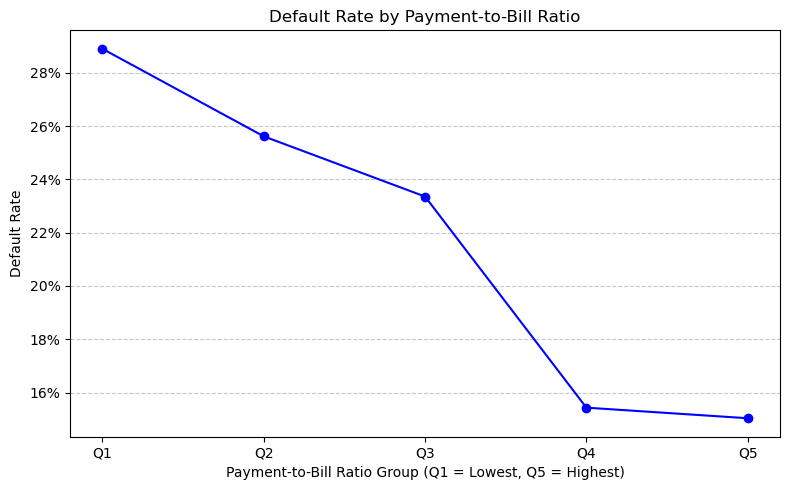

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(len(ratio_default)),
    ratio_default["default_rate"],
    marker="o", color="blue"
)
plt.xticks(
    range(len(ratio_default)),
    [f"Q{i+1}" for i in range(len(ratio_default))]
)
plt.xlabel("Payment-to-Bill Ratio Group (Q1 = Lowest, Q5 = Highest)")
plt.ylabel("Default Rate")
plt.title("Default Rate by Payment-to-Bill Ratio")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Observation:** A lower payment-to-bill ratio is associated with a higher observed default rate. The feature is therefore retained for both predictive modeling and customer risk profiling.


## 3. Feature Engineering and Modeling Dataset

This section keeps the features built in section 2 and organizes them into the model input for next-month default prediction. The order is: select and inspect fields, split train and test sets, then configure preprocessing.

### 3.1 Select and Inspect Modeling Fields

| Feature group | Fields | Purpose |
|---|---|---|
| Profile and credit | `LIMIT_BAL`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Baseline for comparing the contribution of behavioral features |
| Delay behavior | `delay_months` | Number of months with a recorded delay in the past six months |
| Billing behavior | `avg_bill_amt`, `bill_amt_std` | Bill level and volatility, keeping negative bills in the calculation |
| Payment amounts | `avg_payment`, `payment_std` | Payment level and volatility |
| Payment-to-bill relationship | `payment_to_bill_ratio_capped`, `ratio_missing` | Relative repayment level, plus a flag for customers whose ratio cannot be computed |

The model keeps 12 features, and `default` is used only as the prediction target. The EDA group labels do not enter the model, and totals and averages duplicate other fields, so they are not added. Six-month summary features are easy to interpret but omit the most recent status and month-to-month changes, so they cannot be claimed to outperform the raw monthly variables. Section 6 compares feature-group contributions, and section 7 builds a descriptive profile from delay months and the payment-to-bill ratio.

The next cell shows the first five records, data types, and missing values. `SEX`, `EDUCATION`, and `MARRIAGE` are stored as integers but still represent categories; `ratio_missing` is a 0/1 flag.

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

# Keep the features already checked during EDA.
feature_cols = [
    "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "delay_months", "avg_bill_amt", "bill_amt_std",
    "avg_payment", "payment_std",
    "payment_to_bill_ratio_capped", "ratio_missing",
]

categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]
numeric_features = [col for col in feature_cols if col not in categorical_features]

df_model = df[feature_cols + [target_col]].copy()
X = df_model.drop(columns=[target_col])
y = df_model[target_col]

display(df_model.head().T)
feature_check = pd.DataFrame({
    "data_type": df_model.dtypes,
    "missing_count": df_model.isna().sum()
})
display(feature_check)


,0,1,2,3,4
LIMIT_BAL,20000.0000,120000.0000,90000.0000,50000.0000,50000.0000
SEX,2.0000,2.0000,2.0000,2.0000,1.0000
EDUCATION,2.0000,2.0000,2.0000,2.0000,2.0000
MARRIAGE,1.0000,2.0000,2.0000,1.0000,1.0000
AGE,24.0000,26.0000,34.0000,37.0000,57.0000
delay_months,2.0000,2.0000,0.0000,0.0000,0.0000
avg_bill_amt,1284.0000,2846.1667,16942.1667,38555.6667,18223.1667
bill_amt_std,1761.6332,637.9678,6064.5186,10565.7935,10668.5901
avg_payment,114.8333,833.3333,1836.3333,1398.0000,9841.5000
payment_std,281.2831,752.7727,1569.8155,478.0582,13786.2307


,data_type,missing_count
LIMIT_BAL,float64,0
SEX,int64,0
EDUCATION,int64,0
MARRIAGE,int64,0
AGE,int64,0
delay_months,int64,0
avg_bill_amt,float64,0
bill_amt_std,float64,0
avg_payment,float64,0
payment_std,float64,0


**Observation:** `payment_to_bill_ratio_capped` has 1,071 missing values, while the other modeling fields and the target have none. For these customers the six-month bill total is not positive, so a meaningful ratio cannot be computed; the customers are kept with a `ratio_missing` flag, and the ratio is imputed during modeling.

### 3.2 Split and Inspect Train and Test Sets

The data is split 80/20. `stratify=y` keeps the default rate similar in both sets, and `random_state=42` makes the split reproducible. The split happens first, so preprocessing can learn from the training set only. The table checks sample sizes, feature counts, and default rates.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

split_summary = pd.DataFrame({
    "customer_count": [len(X_train), len(X_test)],
    "feature_count": [X_train.shape[1], X_test.shape[1]],
    "default_count": [y_train.sum(), y_test.sum()],
    "default_rate_pct": [y_train.mean() * 100, y_test.mean() * 100]
}, index=["Train", "Test"])
display(split_summary.round(2))


,customer_count,feature_count,default_count,default_rate_pct
Train,24000,12,5309,22.1200
Test,6000,12,1327,22.1200


**Observation:** The training set has 24,000 records and the test set has 6,000. Both have 12 input features, and both have a default rate of 22.12% after rounding.

### 3.3 Configure Preprocessing

Numeric fields are first imputed with the training-set median and then standardized, which helps Logistic Regression handle different amount scales. Categorical fields use one-hot encoding so that category codes are not treated as numeric magnitudes. Both models share the same processing rules; Random Forest does not require standardization.

This cell only defines the rules, so it produces no output. The values, means, standard deviations, and categories are learned when the models call `fit(X_train, y_train)` in section 4, and the test set only applies those rules. The ratio imputation is used for modeling and does not overwrite `df`, so section 7 can still identify customers with a missing ratio.

Section 2 explored the full sample and helped select features, so the later test scores are an exploratory evaluation. The guarantee here is only that preprocessing is not fitted on the test set; it cannot remove the effect of the earlier feature selection.

In [35]:
# Numeric fields are imputed and then standardized.
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Handle numeric and categorical fields separately.
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])


## 4. Predictive Modeling

This section checks whether historical customer features help identify next-month default and compares missed and false defaults. Both models use the same train and test sets from section 3, following the order: train, compare metrics, inspect error types, compare ranking ability, and examine threshold effects.

### 4.1 Train Models and Inspect Predictions

Logistic Regression serves as an interpretable baseline, and Random Forest provides a comparison for nonlinear relationships. Both use `class_weight="balanced"`, which weights the minority default class more heavily based on inverse class frequencies. The parameters are fixed for an initial comparison and are not tuned repeatedly on the test set.

Each model clones the preprocessing rules so that training one model does not change the other model's preprocessing state. Default scores are produced first, and the common 0.5 threshold turns them into 0/1 labels. The models are not probability-calibrated, so the scores cannot be read directly as real default probabilities.

The first ten predictions show how actual labels, scores, and predicted labels line up, but model performance still needs the full test set.

In [36]:
from sklearn.base import clone

# Build a separate preprocessor for each model.
logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42
    ))
])

rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

logistic_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]
y_pred_lr = (y_prob_lr >= 0.5).astype(int)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_pred_rf = (y_prob_rf >= 0.5).astype(int)

prediction_preview = pd.DataFrame({
    "actual_default": y_test,
    "lr_score": y_prob_lr,
    "lr_prediction": y_pred_lr,
    "rf_score": y_prob_rf,
    "rf_prediction": y_pred_rf
})
display(prediction_preview.head(10).round(4))


,actual_default,lr_score,lr_prediction,rf_score,rf_prediction
6907,0,0.4193,0,0.1300,0
24575,0,0.4114,0,0.1700,0
26766,0,0.3945,0,0.1300,0
2156,1,0.2637,0,0.0850,0
3179,0,0.1280,0,0.0600,0
29382,0,0.3052,0,0.3000,0
24454,0,0.3641,0,0.2000,0
23886,0,0.1865,0,0.0450,0
5504,0,0.2239,0,0.1600,0
29720,0,0.3450,0,0.1100,0


### 4.2 Compare Test-Set Metrics

The cell first computes the accuracy of predicting no default for every customer as a reference, then shows the full metrics of both models. That simple rule cannot find any defaulters, so accuracy alone cannot evaluate a model.

| Metric | Question it answers |
|---|---|
| Accuracy | Of all customers, what share is predicted correctly? |
| Precision | Of customers predicted to default, what share actually defaults? |
| Recall | Of customers who actually default, how many are found? |
| F1 | What is the harmonic mean of Precision and Recall? |
| ROC-AUC | Can the model rank defaulters above non-defaulters? |
| PR-AUC (AP) | How well does the model identify defaulters across thresholds? |

The `PR-AUC` column in this table and in the saved reports uses `average_precision_score`, so it is Average Precision (AP), not the trapezoidal area under the PR curve. The first four metrics use the 0.5 threshold, and the last two use the prediction scores directly.

A short `evaluate_model` function keeps both models on the same metric definitions. The table provides exact values, and the bar chart compares the metrics visually.

In [37]:
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob)
    }

model_comparison = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, y_pred_lr, y_prob_lr),
    evaluate_model("Random Forest", y_test, y_pred_rf, y_prob_rf)
])

# Save the model metrics from this run.
model_comparison.round(4).to_csv(REPORTS_DIR / "model_results.csv", index=False)
baseline_accuracy = (y_test == 0).mean()
print(f"Always predict no default: Accuracy = {baseline_accuracy:.2%}")
display(model_comparison.round(4))


Always predict no default: Accuracy = 77.88%


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.7535,0.4541,0.5659,0.5039,0.7501,0.4901
1,Random Forest,0.8007,0.5956,0.3075,0.4056,0.7493,0.4933


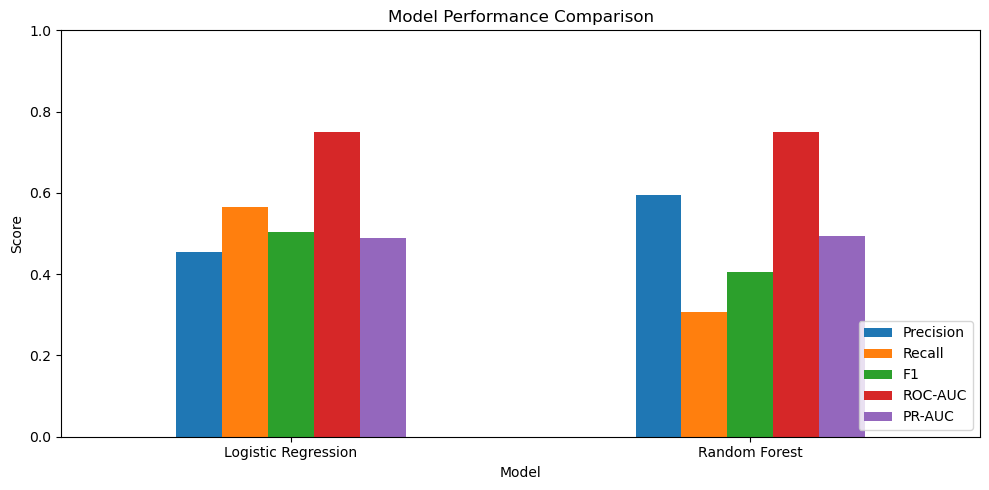

In [38]:
model_plot = model_comparison.set_index("Model")[
    ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
]

model_plot.plot(kind="bar", figsize=(10, 5))
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_model_performance_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


**Observation:** Predicting no default for every customer gives 77.88% accuracy but zero default recall. Logistic Regression reaches 75.35% accuracy and 56.59% recall, while Random Forest reaches 80.07% accuracy and 30.75% recall. Higher accuracy therefore does not mean that more defaulters are found. Logistic Regression has the higher Recall and F1, and Random Forest has the higher Precision; their ROC-AUC and AP values are close, but a single split is not enough to prove equal performance.

### 4.3 Inspect False Positives and False Negatives

The confusion matrices translate the metrics back into customer counts: the upper-right cell is false positives (non-defaulters predicted as defaulters), and the lower-left cell is false negatives (defaulters predicted as non-defaulters). This helps explain the review burden and the missed-default risk that each model may create.

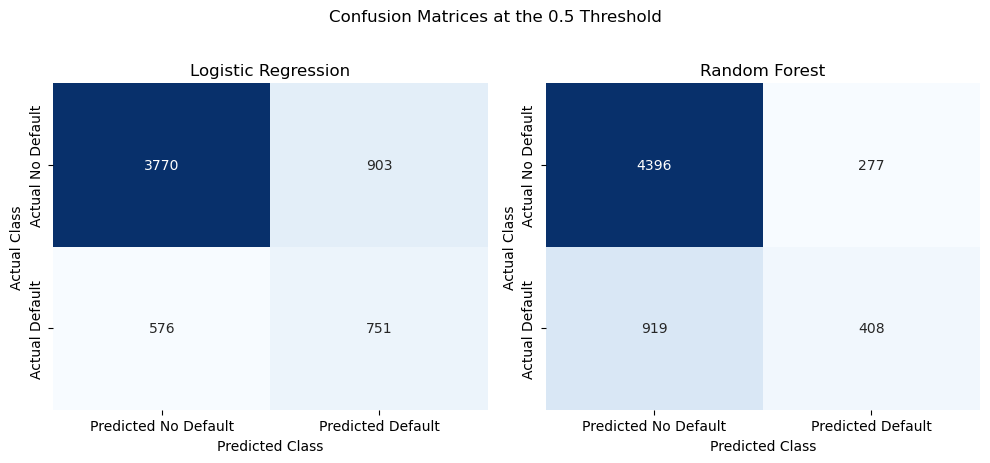

In [39]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Save the error counts of both models.
cm_table = pd.DataFrame([
    {"Model": "Logistic Regression",
     "True Negative": cm_lr[0, 0], "False Positive": cm_lr[0, 1],
     "False Negative": cm_lr[1, 0], "True Positive": cm_lr[1, 1]},
    {"Model": "Random Forest",
     "True Negative": cm_rf[0, 0], "False Positive": cm_rf[0, 1],
     "False Negative": cm_rf[1, 0], "True Positive": cm_rf[1, 1]},
])
cm_table.to_csv(REPORTS_DIR / "confusion_matrices.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, cm, title in zip(
    axes,
    [cm_lr, cm_rf],
    ["Logistic Regression", "Random Forest"]
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Predicted No Default", "Predicted Default"],
        yticklabels=["Actual No Default", "Actual Default"],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

fig.suptitle("Confusion Matrices at the 0.5 Threshold", y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()


**Observation:** The test set contains 1,327 defaulters. Logistic Regression identifies 751, misses 576, and also produces 903 false positives; Random Forest identifies 408, misses 919, and produces 277 false positives. At the current threshold, Logistic Regression finds more defaulters and carries more false positives.

### 4.4 ROC Curves: Compare Ranking Ability

The ROC curve shows the relationship between the false-positive rate and default recall across thresholds. Logistic Regression and Random Forest have ROC-AUC values of about 0.7501 and 0.7493, above the 0.5 of random ranking, but this cannot be read as 75% prediction accuracy.

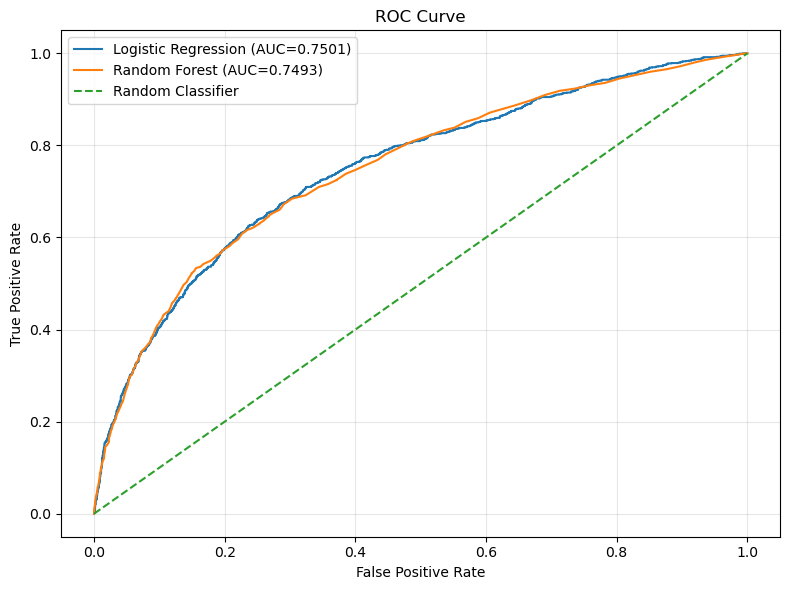

In [40]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={roc_auc_score(y_test, y_prob_lr):.4f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC={roc_auc_score(y_test, y_prob_rf):.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()


### 4.5 PR Curves: Focus on Identifying Defaulters

Defaulters are about 22% of the test set, so it is also worth checking how many predicted defaulters actually default when the model tries to find more of them. The PR curve shows the relationship between Precision and Recall and complements the ROC curve; the horizontal dashed line is the test-set default rate reference, and the legend reports AP.

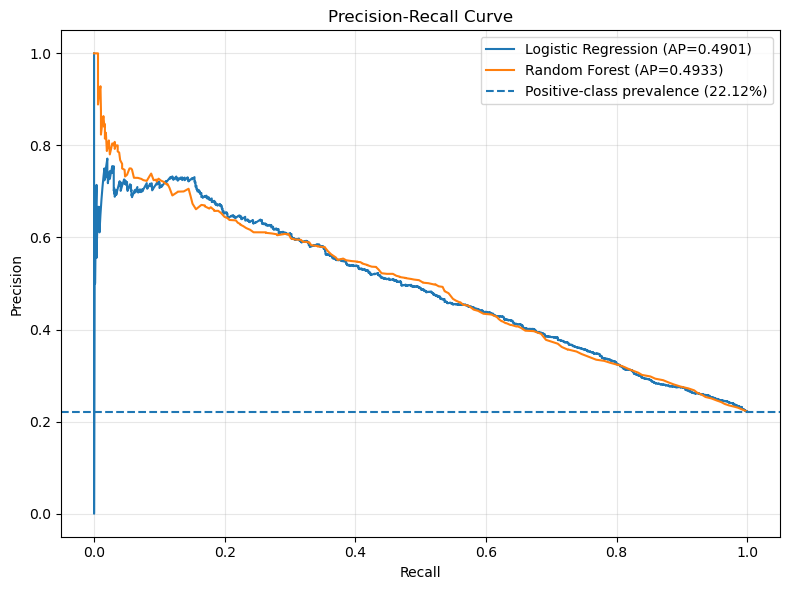

In [41]:
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_prob_lr)
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_prob_rf)
baseline = y_test.mean()

plt.figure(figsize=(8, 6))
plt.plot(
    recall_lr, precision_lr,
    label=f"Logistic Regression (AP={average_precision_score(y_test, y_prob_lr):.4f})"
)
plt.plot(
    recall_rf, precision_rf,
    label=f"Random Forest (AP={average_precision_score(y_test, y_prob_rf):.4f})"
)
plt.axhline(baseline, linestyle="--", label=f"Positive-class prevalence ({baseline:.2%})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_precision_recall_curve.png", dpi=300, bbox_inches="tight")
plt.show()


**Observation:** The two models have AP values of about 0.4901 and 0.4933, above the class-rate reference of about 0.2212. This shows that the scores help identify defaulters. It does not mean that the model predicts 49% of customers will default, and it does not provide a ready-to-use business threshold.

### 4.6 Threshold Analysis: Inspect the False-Positive and False-Negative Trade-Off

Using Logistic Regression as the example, the model and scores stay fixed while only the threshold for predicting default changes. Lowering the threshold marks more customers as defaulters, so Recall does not decrease; Precision may fluctuate and cannot be assumed to change monotonically in every dataset.

Besides the metrics, the table shows false positives and false negatives. It only demonstrates the effect of the threshold and does not select a best threshold from the test set; later comparisons still use the preset 0.5. A formal threshold choice would need a separate validation set and explicit business costs for both error types.

In [42]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
threshold_results = []

for threshold in thresholds:
    pred = (y_prob_lr >= threshold).astype(int)
    threshold_cm = confusion_matrix(y_test, pred)
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "False Positive": threshold_cm[0, 1],
        "False Negative": threshold_cm[1, 0]
    })

threshold_results = pd.DataFrame(threshold_results)
threshold_results.round(4)


,Threshold,Accuracy,Precision,Recall,F1,False Positive,False Negative
0,0.2000,0.2705,0.2316,0.9917,0.3755,4366,11
1,0.3000,0.3857,0.2570,0.9397,0.4036,3606,80
2,0.4000,0.6483,0.3584,0.7468,0.4844,1774,336
3,0.5000,0.7535,0.4541,0.5659,0.5039,903,576
4,0.6000,0.7825,0.5092,0.4567,0.4815,584,721
5,0.7000,0.7990,0.5741,0.3534,0.4375,348,858
6,0.8000,0.8032,0.6367,0.2562,0.3654,194,987


**Observation:** When the threshold moves from 0.5 to 0.3, Logistic Regression Recall rises from 56.59% to 93.97% and Precision falls from 45.41% to 25.70%; false negatives drop from 576 to 80, and false positives rise from 903 to 3,606. Whether this is worthwhile depends on the actual costs. The metrics and error counts at 0.5 match the earlier model comparison and confusion matrices.

**Section conclusion:** With the current data, 12 features, and one stratified split, both models reach a ROC-AUC of about 0.75 and an AP of about 0.49, indicating that the feature combination carries some ability to distinguish default. At the 0.5 threshold, Logistic Regression finds more defaulters and Random Forest produces fewer false positives. This supports the prediction part of the project, but the overall metrics cannot show which feature contributes most or prove real business benefit.

Next, section 5 explains what information the models use, section 6 compares feature-group contributions, and section 7 builds the descriptive customer profile. The profile remains a rule-based grouping and does not replace profile labels with model predictions. The full-sample EDA limitation described in section 3 still applies, and the current results are an exploratory evaluation.

## 5. Model Interpretation

Section 4 checked whether the models can distinguish defaulters. This section continues by looking at what information the models use: Random Forest importance first, then Logistic Regression coefficients and their meaning, and finally the connection with the EDA results in section 2. Both types of interpretation come from already trained models and do not imply causation.

### 5.1 Random Forest Feature Importance

Importance measures the impurity reduction that a feature provides in tree splits and is normalized to sum to 1. The top 10 values are kept as both a table and a bar chart: the table is easy to verify and the chart is easy to compare. The field-name mapping is also kept, which helps readers understand the encoded variables.

These scores do not mean that risk rises or falls, and they are not equal to an increase in prediction accuracy. Variables with more distinct values may more easily receive a higher score; correlated features may share or substitute for each other's information, and information from categorical variables is spread across several encoded columns. They therefore cannot show the independent contribution of a feature group by themselves.

In [43]:
# Inspect Random Forest feature importance.
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
}).sort_values("importance", ascending=False).reset_index(drop=True)

feature_name_mapping = {
    "num__delay_months": "Number of Delayed Months",
    "num__bill_amt_std": "Bill Amount Volatility",
    "num__payment_to_bill_ratio_capped": "Payment-to-Bill Ratio",
    "num__avg_payment": "Average Payment",
    "num__avg_bill_amt": "Average Bill",
    "num__payment_std": "Payment Volatility",
    "num__LIMIT_BAL": "Credit Limit",
    "num__AGE": "Age",
    "num__ratio_missing": "Missing Ratio Indicator",
    "cat__EDUCATION_1": "Education: 1 (Graduate)",
    "cat__EDUCATION_2": "Education: 2 (University)",
    "cat__EDUCATION_3": "Education: 3 (High School)",
    "cat__EDUCATION_4": "Education: 4 (Other/Unknown)",
    "cat__SEX_1": "Sex: 1",
    "cat__SEX_2": "Sex: 2",
    "cat__MARRIAGE_1": "Marriage: 1",
    "cat__MARRIAGE_2": "Marriage: 2",
    "cat__MARRIAGE_3": "Marriage: 3"
}

feature_importance_plot = feature_importance.copy()
feature_importance_plot["feature"] = (
    feature_importance_plot["feature"]
    .map(feature_name_mapping)
    .fillna(feature_importance_plot["feature"])
)

# Save the top 10 feature-importance values.
feature_importance_plot.head(10).round(4).to_csv(
    REPORTS_DIR / "feature_importance.csv", index=False
)
feature_importance_plot.head(10)


,feature,importance
0,Number of Delayed Months,0.1539
1,Bill Amount Volatility,0.1186
2,Payment-to-Bill Ratio,0.1169
3,Average Payment,0.1153
4,Average Bill,0.1131
5,Payment Volatility,0.1113
6,Credit Limit,0.0961
7,Age,0.0949
8,Education: 2 (University),0.0123
9,Education: 1 (Graduate),0.0110


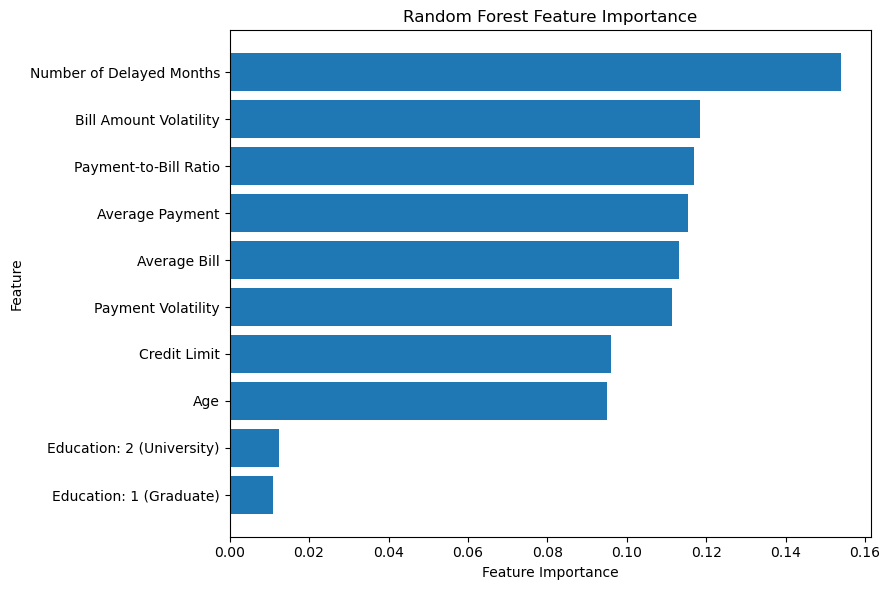

In [44]:
top10 = feature_importance_plot.head(10).sort_values("importance")

plt.figure(figsize=(9, 6))
plt.barh(top10["feature"], top10["importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_random_forest_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


**Observation:** `delay_months` has the highest importance, about 0.1539, followed by `bill_amt_std` (0.1186) and `payment_to_bill_ratio_capped` (0.1169). The top features concentrate on delay, billing, and payment behavior, showing that this information is used more often in the current Random Forest splits. The value 0.1539 cannot be read as a 15.39% increase in default probability caused by delay, and it does not directly prove how much prediction performance improves when delay features are added.

### 5.2 Logistic Regression Coefficients

The table below shows all 18 encoded feature coefficients instead of only the top 15. `abs_coefficient` is used only for sorting, and the original signs are kept; because variable units differ, this order is not a unified feature-importance ranking.

| Variable type | How to read the coefficient |
|---|---|
| Numeric variables such as `delay_months` and `avg_payment` | The change in the model linear score for a one-standard-deviation increase in the training set, not for one raw unit |
| Binary flag `ratio_missing` | It is also standardized, so the score change from 0 to 1 should be read as the coefficient divided by its standardization scale |
| Categorical variables such as `cat__SEX_1` and `cat__SEX_2` | The current encoding keeps all categories without an omitted reference category; moving from SEX=1 to SEX=2 compares the difference between the two coefficients |

The linear score here is the model log-odds of default, not a predicted probability between 0 and 1. Coefficient interpretation holds other inputs constant; because engineered features are related to each other, a single coefficient cannot be read as the real-world effect of changing one behavior.

This section keeps the coefficient table and does not compute a uniform `odds_ratio` for every variable. These coefficients come from a regularized, class-weighted model, so they are not used to claim statistical significance or causation.

In [45]:
# Inspect the coefficients of all encoded features.
lr_preprocessor = logistic_model.named_steps["preprocessor"]
lr_classifier = logistic_model.named_steps["classifier"]

lr_feature_names = lr_preprocessor.get_feature_names_out()
coef_df = pd.DataFrame({
    "feature": lr_feature_names,
    "coefficient": lr_classifier.coef_[0]
})
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()

coef_df.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)


,feature,coefficient,abs_coefficient
0,num__delay_months,0.8145,0.8145
1,num__avg_payment,-0.7665,0.7665
2,cat__EDUCATION_4,-0.7183,0.7183
3,num__payment_std,0.4584,0.4584
4,num__LIMIT_BAL,-0.2587,0.2587
5,cat__EDUCATION_2,0.2042,0.2042
6,num__avg_bill_amt,0.1996,0.1996
7,num__ratio_missing,0.1897,0.1897
8,cat__EDUCATION_1,0.1885,0.1885
9,cat__SEX_2,-0.1627,0.1627


**Observation:** The coefficient of `delay_months` is about +0.8145, and the coefficient of `avg_payment` is about -0.7665. In the current Logistic Regression, more delayed months correspond to a higher model score and a higher average payment corresponds to a lower score; this matches the direction of the corresponding EDA group trends but cannot be read as a causal effect.

The coefficient of `payment_to_bill_ratio_capped` is about +0.0914, while section 2 showed a lower default rate in groups with a higher ratio. EDA describes the marginal group relationship of one variable, while a logistic coefficient describes the conditional relationship once several variables enter the model together, so the two cannot replace each other directly. The sign difference may relate to correlations between features and the linear model specification; the current results are not enough to determine the exact cause, and they must not be read as "paying more raises risk".

**Section conclusion:** Delay, billing, and payment information deserves attention in the current model, but importance rankings and coefficients alone cannot prove that one feature group provides the largest prediction gain. Section 6 compares metric changes as feature groups are added step by step, and section 7 presents a descriptive customer profile using observed default rates.

## 6. Feature Group Contribution

This section answers one question: how much does model performance improve when four behavioral feature groups -- delay behavior, payment-to-bill relationship, billing behavior, and payment amounts -- are added step by step to profile and credit variables?

To avoid mixing delay with the payment ratio, the section follows the grouping from section 3 and splits them into two stages, comparing five cumulative feature sets. Each group's added information and contribution can then be seen separately.

In [46]:
baseline_features = ["AGE", "SEX", "EDUCATION", "MARRIAGE", "LIMIT_BAL"]
delay_features = ["delay_months"]
ratio_features = ["payment_to_bill_ratio_capped", "ratio_missing"]
billing_features = ["avg_bill_amt", "bill_amt_std"]
payment_features = ["avg_payment", "payment_std"]

# Five feature sets add one group at a time.
feature_sets = {
    "Demographic + Credit": baseline_features,
    "+ Delay Behavior": baseline_features + delay_features,
    "+ Payment-to-Bill Behavior": baseline_features + delay_features + ratio_features,
    "+ Billing Behavior": baseline_features + delay_features + ratio_features + billing_features,
    "+ Payment Behavior": baseline_features + delay_features + ratio_features + billing_features + payment_features
}

def build_logistic_pipeline(selected_features):
    # Build preprocessing and Logistic Regression for each feature set without repeating the code five times.
    categorical = [c for c in ["SEX", "EDUCATION", "MARRIAGE"] if c in selected_features]
    numeric = [c for c in selected_features if c not in categorical]
    prep = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
    ])
    return Pipeline([
        ("preprocessor", prep),
        ("classifier", LogisticRegression(
            max_iter=1000, class_weight="balanced", random_state=42
        ))
    ])

feature_group_rows = []
for name, features in feature_sets.items():
    model = build_logistic_pipeline(features)
    model.fit(X_train[features], y_train)
    prob = model.predict_proba(X_test[features])[:, 1]
    pred = (prob >= 0.5).astype(int)
    feature_group_rows.append({
        "Feature Set": name,
        "ROC-AUC": roc_auc_score(y_test, prob),
        "F1": f1_score(y_test, pred)
    })

feature_group_results = pd.DataFrame(feature_group_rows)
feature_group_results["Delta ROC-AUC"] = feature_group_results["ROC-AUC"].diff()

# Save the results so reports/feature_group_results.csv matches this run.
feature_group_results.round(4).to_csv(
    REPORTS_DIR / "feature_group_results.csv", index=False
)
feature_group_results.round(4)

,Feature Set,ROC-AUC,F1,Delta ROC-AUC
0,Demographic + Credit,0.6027,0.3823,NaN
1,+ Delay Behavior,0.7296,0.4879,0.1269
2,+ Payment-to-Bill Behavior,0.7409,0.5009,0.0113
3,+ Billing Behavior,0.7411,0.5012,0.0003
4,+ Payment Behavior,0.7501,0.5039,0.0090


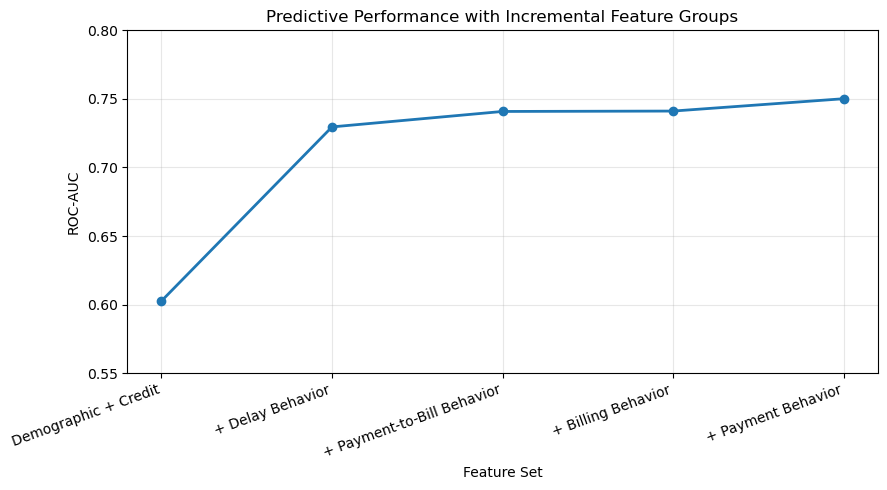

In [47]:
plt.figure(figsize=(9, 5))
plt.plot(
    feature_group_results["Feature Set"],
    feature_group_results["ROC-AUC"],
    marker="o", linewidth=2
)
plt.ylabel("ROC-AUC")
plt.xlabel("Feature Set")
plt.title("Predictive Performance with Incremental Feature Groups")
plt.ylim(0.55, 0.80)
plt.xticks(rotation=20, ha="right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_feature_group_contribution.png", dpi=300, bbox_inches="tight")
plt.show()

**Observation:** Profile and credit variables alone reach ROC-AUC 0.6027. Adding delay behavior raises it to 0.7296 (+0.1269), the largest step of the five groups, showing that delay months already carry strong risk information.

Adding the payment-to-bill relationship raises it to 0.7409 (+0.0113). The repayment coverage therefore adds information beyond the delay count, and the two should not be merged into one group. Adding billing behavior raises it only to 0.7411 (+0.0003), while payment amounts add 0.0090. With all features included, ROC-AUC is 0.7501, matching the Logistic Regression result in section 4.

**Section conclusion:** In the current data, delay behavior is the main feature group for default prediction; the payment-to-bill relationship provides observable extra information beyond the delay count, but with a clearly smaller increment; billing level contributes little once the other information is included. This comparison remains exploratory, the group order is chosen by the author, and results may change with another model or feature order.

## 7. Customer Risk Profiling

This section turns model-related variables into an easy-to-understand customer profile. The profile uses two variables: `delay_months` (number of delayed months) and `payment_to_bill_ratio_capped` (cumulative payment-to-bill ratio, capped at 5 to keep a few extreme values from stretching the bin boundaries); customers whose ratio cannot be computed are labeled Unknown.

| Variable | Bins |
|---|---|
| Delay months | 0 months / 1-2 months / 3-6 months |
| Payment-to-bill ratio | Thirds of the valid ratio: Low / Medium / High |

The combinations are merged into four profiles by the following rules. These rules are a descriptive, manually chosen grouping, not a model prediction:

- Low Risk: 0 delayed months and a ratio not in the lowest tercile;
- High Risk: 3-6 delayed months and a ratio not in the highest tercile;
- Medium Risk: all other combinations with a computable ratio;
- Unknown: bill total <= 0, so the ratio cannot be computed.

In [48]:
# Bin delay months: 0 / 1-2 / 3-6 months.
df["delay_group"] = pd.cut(
    df["delay_months"],
    bins=[-1, 0, 2, 6],
    labels=["Low", "Medium", "High"]
)

# Split the capped payment-to-bill ratio into Low / Medium / High thirds.
df["payment_ratio_group"] = pd.qcut(
    df["payment_to_bill_ratio_capped"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# Cross-tabulate customer counts and observed default rates for each delay and ratio bin.
risk_pattern = (
    df.groupby(["delay_group", "payment_ratio_group"], observed=True)[target_col]
      .agg(customer_count="count", default_rate="mean")
      .reset_index()
)
risk_pattern["default_rate"] *= 100
risk_pattern.round(2)

,delay_group,payment_ratio_group,customer_count,default_rate
0,Low,Low,5957,11.4800
1,Low,Medium,6222,10.6200
2,Low,High,7340,11.7700
3,Medium,Low,1612,38.7100
4,Medium,Medium,1976,34.8200
5,Medium,High,2083,24.1500
6,High,Low,2074,63.3100
7,High,Medium,1445,57.5100
8,High,High,220,45.4500


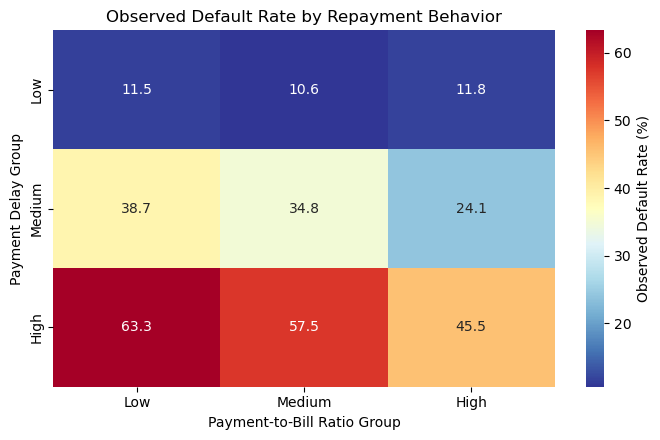

In [49]:
risk_heatmap = risk_pattern.pivot(
    index="delay_group",
    columns="payment_ratio_group",
    values="default_rate"
)

# The heatmap covers only customers with a computable payment-to-bill ratio; missing ratios go to the Unknown profile.
plt.figure(figsize=(7, 4.5))
sns.heatmap(
    risk_heatmap,
    annot=True,
    fmt=".1f",
    cmap="RdYlBu_r",
    cbar_kws={"label": "Observed Default Rate (%)"}
)
plt.xlabel("Payment-to-Bill Ratio Group")
plt.ylabel("Payment Delay Group")
plt.title("Observed Default Rate by Repayment Behavior")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_repayment_behavior_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

**Key observation:** Among customers with recorded delays, the payment-to-bill ratio adds further separation: in the Medium delay bin the observed default rate falls from 38.71% to 24.15%, and in the High delay bin from 63.31% to 45.45%. However, the High delay / High ratio cell contains only 220 customers, so this result needs cautious interpretation.

Among customers with no delay (the Low bin), the observed default rates across the three ratio bins are 11.48%, 10.62%, and 11.77%, which is a very small difference. The payment-to-bill ratio mainly matters once delays are already recorded, rather than being equally important for all customers.

In [50]:
df["repayment_risk_profile"] = "Medium Risk"

ratio_missing = df["payment_ratio_group"].isna()

df.loc[
    (~ratio_missing) &
    (df["delay_group"] == "Low") &
    (df["payment_ratio_group"].isin(["Medium", "High"])),
    "repayment_risk_profile"
] = "Low Risk"

df.loc[
    (~ratio_missing) &
    (df["delay_group"] == "High") &
    (df["payment_ratio_group"].isin(["Low", "Medium"])),
    "repayment_risk_profile"
] = "High Risk"

df.loc[ratio_missing, "repayment_risk_profile"] = "Unknown"

profile_summary = (
    df.groupby("repayment_risk_profile", observed=False)
      .agg(
          customer_count=(target_col, "size"),
          default_rate=(target_col, "mean"),
          avg_age=("AGE", "mean"),
          avg_credit_limit=("LIMIT_BAL", "mean"),
          avg_bill=("avg_bill_amt", "mean"),
          avg_payment=("avg_payment", "mean"),
          avg_payment_ratio=("payment_to_bill_ratio_capped", "mean"),
          avg_delay_months=("delay_months", "mean")
      )
      .reset_index()
)
profile_summary["default_rate"] *= 100

# Show the profiles in a readable order instead of alphabetical order
profile_order = ["Low Risk", "Medium Risk", "High Risk", "Unknown"]
profile_summary = (
    profile_summary.set_index("repayment_risk_profile")
    .loc[profile_order]
    .reset_index()
)

# Keep reports/customer_risk_profiles.csv in sync with this run
profile_summary.rename(columns={
    "repayment_risk_profile": "Profile",
    "customer_count": "Customer Count",
    "default_rate": "Observed Default Rate"
})[["Profile", "Customer Count", "Observed Default Rate"]].round(4).to_csv(
    REPORTS_DIR / "customer_risk_profiles.csv", index=False
)
profile_summary.round(2)


,repayment_risk_profile,customer_count,default_rate,avg_age,avg_credit_limit,avg_bill,avg_payment,avg_payment_ratio,avg_delay_months
0,Low Risk,13562,11.2400,35.4400,193624.1000,28597.9700,7656.0000,0.5900,0.0000
1,Medium Risk,11848,21.9400,35.5600,156033.0600,65577.9100,3804.9600,0.2500,0.7000
2,High Risk,3519,60.9300,35.0400,92426.8300,52526.6800,2483.5600,0.0600,4.5500
3,Unknown,1071,34.3600,36.7600,209775.9100,-322.9100,565.3400,NaN,0.6400


**Why is there an Unknown group?**

Customers with a bill total of zero or below cannot have a meaningful payment-to-bill ratio, so they are labeled Unknown instead of being forced into one of the risk bins.

Their observed default rate falls between the Medium Risk and High Risk groups, but because the ratio is missing they should not be treated directly as a fourth risk tier or compared with the other profiles without care.

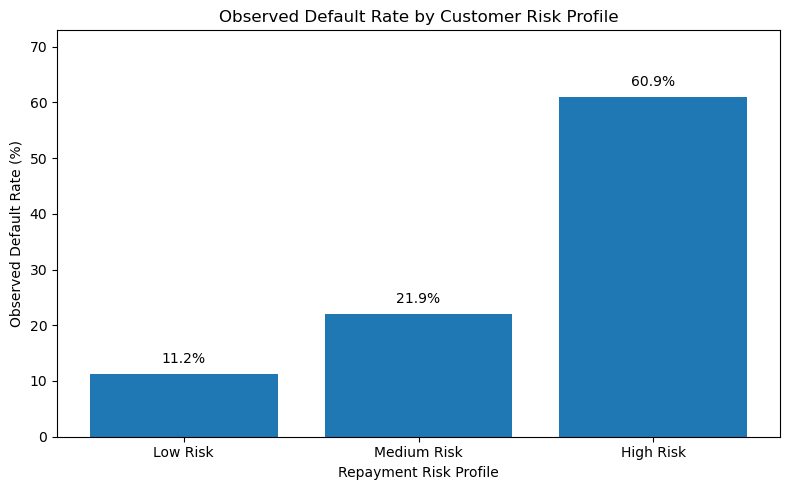

In [51]:
profile_plot = profile_summary[
    profile_summary["repayment_risk_profile"].isin(["Low Risk", "Medium Risk", "High Risk"])
].copy()

profile_plot = profile_plot.set_index("repayment_risk_profile").loc[
    ["Low Risk", "Medium Risk", "High Risk"]
]

plt.figure(figsize=(8, 5))
plt.bar(profile_plot.index, profile_plot["default_rate"])
plt.ylabel("Observed Default Rate (%)")
plt.xlabel("Repayment Risk Profile")
plt.title("Observed Default Rate by Customer Risk Profile")
for i, value in enumerate(profile_plot["default_rate"]):
    plt.text(i, value + 2, f"{value:.1f}%", ha="center")
plt.ylim(0, max(profile_plot["default_rate"]) + 12)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "08_customer_risk_profile_default_rate.png", dpi=300, bbox_inches="tight")
plt.show()


## 7.1 What type of customer is more likely to default?

Based on the descriptive profile, customers with a higher observed default rate usually show the following characteristics:

- multiple months with payment delays;
- a relatively low payment-to-bill ratio;
- lower average payment amounts;
- relatively lower credit limits within this dataset.

In the current sample, the High Risk profile has an observed default rate of about **60.9%**, compared with about **11.2%** for Low Risk, a clear difference. These characteristics are related to each other and only describe customer patterns in the data; they cannot be read as causal effects or used directly for real credit decisions.

## 7.2 Customer Profile Summary

| Profile | Typical characteristics | Observed default rate |
|---|---|---:|
| **Low Risk** | 0 delayed months; ratio not in the lowest tercile; average payment about 7,656 | ~11.2% |
| **Medium Risk** | all other combinations with a computable ratio; average delay about 0.70 months | ~21.9% |
| **High Risk** | 3-6 delayed months and ratio not in the highest tercile; average delay about 4.55 months; average credit limit about 92,427 | ~60.9% |
| **Unknown** | bill total <= 0, so the ratio cannot be computed; average delay about 0.64 months | ~34.4% |

The **Unknown** group is kept separate so that it is not forced into Medium Risk; it should not be treated as a fourth risk tier or compared directly with the first three groups.

## 8. Key Findings

### 1. Delay behavior is the strongest incremental information source

Feature-group analysis shows that adding `delay_months` raises ROC-AUC from **0.6027 to 0.7296** (+0.1269), the largest single step. This indicates that historical payment delays contain substantial information for distinguishing default outcomes in this dataset.

### 2. Payment-to-bill behavior adds information beyond delay counts

After delay behavior is included, the payment-to-bill ratio raises ROC-AUC from **0.7296 to 0.7409** (+0.0113), and payment amount measures add a further **+0.0090**. This is why the project does not rely on `delay_months` alone.

### 3. The customer risk profile reveals a clear behavioral pattern

In the rule-based descriptive profile, the High Risk group has an observed default rate of about **60.9%**, compared with about **11.2%** for the Low Risk group. The High Risk group also averages about 4.55 delayed months and a payment-to-bill ratio of about 0.06.

### 4. Model performance involves a precision-recall trade-off

Logistic Regression (Precision 45.41%, Recall 56.59%) and Random Forest (Precision 59.56%, Recall 30.75%) have similar ranking ability (ROC-AUC 0.7501 and 0.7493) but behave differently at the 0.5 threshold. Logistic Regression captures more defaulters, while Random Forest raises fewer false alerts; the appropriate operating point depends on the relative cost of the two error types.

### 5. The project connects prediction with customer-level interpretation

Instead of stopping at model metrics, the analysis translates statistical and machine-learning results into an interpretable customer profile. This creates an end-to-end data science workflow relevant to financial risk analysis.

## 9. Limitations

1. **Single dataset:** Results may not generalize to other institutions or customer populations.
2. **Observational analysis:** Associations should not be interpreted as causal relationships.
3. **Feature construction:** `delay_months` and `payment_to_bill_ratio_capped` are constructed proxies rather than direct measures of financial capacity.
4. **Model scope:** The project intentionally focuses on Logistic Regression and Random Forest rather than adding advanced models only for complexity.
5. **Class imbalance:** Default cases are a minority, so Accuracy alone is insufficient.
6. **Validation scope:** The features, feature groups, and profiling rules were chosen after exploratory analysis of the full sample, and model evaluation uses one stratified train-test split. Cross-validation, probability calibration, fairness analysis, and external validation would be needed before practical deployment.

## 10. Conclusion

This project examined whether demographic, credit, billing, and payment behavior could be used to understand and predict credit card default.

The analysis found that **delay behavior provides the strongest incremental predictive information**, while the payment-to-bill ratio and payment amount measures add smaller but measurable gains. The customer profiling analysis further shows a clear observed pattern: customers with repeated payment delays and lower payment-to-bill ratios have substantially higher default rates in this dataset.

The project therefore combines three levels of analysis:

1. **Descriptive analysis:** What does the customer data look like?
2. **Predictive analysis:** Can customer characteristics help distinguish default outcomes?
3. **Customer profiling:** What observable repayment patterns characterize groups with different default rates?

The result is an interpretable financial-risk analysis rather than a claim of causal credit-risk prediction.

## 11. Future Work

The current project is intentionally scoped as a practical and interpretable first data science project. Possible extensions include:

- cross-validation to assess model stability;
- probability calibration for more reliable risk probabilities;
- threshold selection based on explicit business costs;
- comparison with a small number of gradient-boosting models;
- individual-level explainability such as SHAP when computationally appropriate;
- subgroup performance and fairness analysis;
- validation on an external credit-risk dataset.

These are proposed extensions and are **not presented as completed work** in this project.


---

# Portfolio Summary

**Project theme:** Credit Default Prediction and Customer Risk Profiling  
**Domain:** Financial Risk / Credit Analytics  
**Tools:** Python, pandas, NumPy, matplotlib, seaborn, scikit-learn  
**Methods:** EDA, feature engineering, Logistic Regression, Random Forest, ROC-AUC, PR-AUC, threshold analysis, feature importance, customer segmentation

**Main takeaway:** Historical repayment behavior shows the clearest relationship with default outcomes in this dataset. Delay months produce the largest incremental gain in ROC-AUC (+0.1269), the payment-to-bill ratio adds a smaller increment (+0.0113), and the rule-based customer profile separates groups with observed default rates of about 11.2% and 60.9%. The project converts these findings into an interpretable customer risk profile while clearly separating descriptive association from causal claims.

## 12. Portfolio Results Snapshot

The repository also includes selected exported figures under `figures/` so that the main results can be reviewed without executing the notebook.

### Model discrimination

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| ROC-AUC | 0.7501 | 0.7493 |
| PR-AUC | 0.4901 | 0.4933 |
| F1 | 0.5039 | 0.4056 |
| Precision | 0.4541 | 0.5956 |
| Recall | 0.5659 | 0.3075 |

The ROC curves are generated by the modeling section. The README uses the exported summary figures so that the headline results remain viewable without shipping the raw dataset.

### Selected figures

![Model performance comparison](../figures/01_model_performance_comparison.png)

![Confusion matrices](../figures/02_confusion_matrices.png)

![Random Forest feature importance](../figures/05_random_forest_feature_importance.png)

![Feature-group contribution](../figures/06_feature_group_contribution.png)

![Customer risk profile](../figures/08_customer_risk_profile_default_rate.png)